# 07. Claim support, contradiction and abstention

## Problem

A real source, valid revision and exact quotation can accompany an unsupported claim. Separate provenance validation from semantic support and retain conflicting authorities.

## Learning objectives

Validate references and quote fidelity; reject unsupported role transfer; compare human-curated policy slots; diagnose false positive graders; preserve abstention.

Run top to bottom in a fresh kernel. The lab uses actual model calls, tools and temporary local storage. Configure the services before execution. Every plotted value declares its measurement kind.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
os.chdir(ROOT)
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings( deep_lab_mode="live", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "live" and not settings.langfuse_enabled

## Concept explanation

## Existing Northstar retrieval architecture

Your repository already implements a meaningful hybrid retrieval pipeline.

The actual repository also validates embedding profiles and handles revision cleanup.

This is worth understanding before adding an "agentic" layer.

## BM25: lexical relevance

BM25 is a ranking function designed around term matching, term frequency, document frequency, and document length.

A common BM25 formulation is:

$$ \operatorname{BM25}(q,d) = \sum_{t\in q} \operatorname{IDF}(t) \frac{f(t,d)(k_1+1)} {f(t,d)+k_1(1-b+b|d|/\overline{|d|})} $$

Here:

- $ f(t,d) $ is the frequency of term $ t $ in document $ d $.
- $ |d| $ is document length.
- $ \overline{|d|} $ is average document length.
- $ \operatorname{IDF}(t) $ reflects term rarity.
- $ k_1 $ controls term-frequency saturation.
- $ b $ controls document-length normalization.

The exact IDF variant and search behavior depend on the engine.

### **Why term rarity matters**

Suppose the user searches:

> SEV-1 incident commander

The term "incident" may appear throughout the corpus.

"SEV-1" and "commander" may be more discriminative.

BM25 accounts for that distinction.

It is particularly useful for exact policy names, identifiers, unusual terminology, and specific error codes.

Production Northstar delegates BM25 to OpenSearch. The notebook reimplements it to expose the ranking arithmetic.

The purpose of learning the formula is understanding why a keyword result ranks highly or poorly.

## Vector retrieval: semantic similarity

An embedding model transforms text into a numerical vector:

$$ f(\text{text}) \rightarrow \mathbf{v}\in\mathbb{R}^d $$

A query and document passage are embedded into a comparable vector space.

A common similarity measure is cosine similarity:

$$ \operatorname{cosine}(a,b) = \frac{a\cdot b} {\\|a\\|\\|b\\|} $$

```
Query:
Who coordinates responders during a major outage?

Document:
The Incident Commander coordinates SEV-1 responders.
```

The wording is different, but vector retrieval may recognize semantic similarity.

### **Limitations**

Vector similarity is not proof of factual relevance.

A passage about restore authorization may be semantically close to a question about incident command without answering it.

Vectors also depend on the embedding model, preprocessing, and indexing configuration. Changing models without rebuilding the index can invalidate the meaning of existing vectors even when dimensions match.

Northstar already accounts for embedding-profile compatibility.

## Reciprocal rank fusion

BM25 and vector scores generally occupy different scales.

Combining raw scores directly can therefore be misleading.

Reciprocal rank fusion (RRF) combines rankings instead:

$$ \operatorname{RRF}(d) = \sum_{r \in R} \frac{1}{k+\operatorname{rank}_r(d)} $$

The repository uses `k=60`.

Suppose:

| Document | BM25 rank | Vector rank |
| -------- | --------- | ----------- |
| A        | 1         | 3           |
| B        | 2         | 1           |
| C        | 3         | 2           |

The combined scores are:

$$ A=\frac{1}{61}+\frac{1}{63} $$

$$ B=\frac{1}{62}+\frac{1}{61} $$

$$ C=\frac{1}{63}+\frac{1}{62} $$

RRF rewards documents that appear prominently across retrieval methods.

The `seen` set prevents one retrieval list from counting duplicate IDs repeatedly.

The result is a ranked list, not a statement that any document supports a particular conclusion.

## Agentic retrieval: retrieve according to uncertainty

Direct RAG generally performs a predetermined retrieval operation.

Agentic retrieval allows subsequent retrieval steps to depend on intermediate findings.

Northstar begins with:

> Compare restore and incident approval responsibilities.

A useful bounded sequence is:

```
1. Search restore authorization.
2. Search incident coordination.
3. Identify the unresolved intersection.
4. Search specifically for joint approval or role transfer.
5. Stop if sufficient evidence is found,
   or report the unresolved question.
```

The agent should not search indefinitely.

### **Query decomposition**

A broad question can be decomposed into narrower evidence requirements.

```
questions = [    "Who approves production restoration?",    "Who coordinates SEV-1 response?",    "Does any current policy assign joint authority?",]
```

This improves observability because every subquestion has an expected evidence category.

### **Bounded query reformulation**

A retrieval policy might allow one targeted reformulation after an empty result, then require abstention or escalation.

The model should not repeatedly issue semantically identical queries merely because no answer was found.

### **Optional reranking**

A reranker examines a smaller candidate set and estimates query-document relevance more directly.

A typical pipeline is:

```
BM25 + vector retrieval
        â†“
RRF top 20
        â†“
Optional reranker
        â†“
Top 5 evidence passages
        â†“
Claim verification
```

Reranking can improve selection but adds latency, model dependencies, and another component to evaluate.

For Northstar's small fictional corpus, hybrid retrieval may already be sufficient.

## Structured claims

Instead of treating the entire answer as one unverifiable string, represent factual findings as separate claims.

A supported example:

```
{
  "text": "The database operations lead approves production restores.",
  "references": [
    {
      "evidence_id": "northstar-restore",
      "revision": "4",
      "quote": "The database operations lead approves production restores."
    }
  ]
}
```

An unsupported example:

```
{
  "text": "The Database Operations Lead automatically becomes Incident Commander.",
  "references": [
    {
      "evidence_id": "northstar-restore",
      "revision": "4",
      "quote": "The database operations lead approves production restores."
    }
  ]
}
```

The second reference resolves to a real bundled passage. Its content does not establish the claim. Support is a separate Verdict, rather than a self-declared property of the Claim record.

Human-readable source aliases identify the fictional policy documents. The existing repository generates bracketed citation tokens derived from evidence IDs, such as `[[<12-character-hash>]]`. In an actual integration, resolve those exact tokens back to the corresponding stored evidence records rather than relying on a human-readable alias.

## Three levels of citation correctness

| Check             | Question                                                   |
| ----------------- | ---------------------------------------------------------- |
| Citation validity | Does the citation resolve to a real evidence record?       |
| Citation coverage | Does every factual claim have an appropriate citation?     |
| Claim support     | Does the referenced evidence actually establish the claim? |

These properties are independent.

An answer could have 100% citation coverage and still contain unsupported claims.

The save tool validates citation membership. `evidence.py` adds revision and exact-quote checks, a conservative complete-sentence verifier, and an optional model-judge adapter. Human review remains responsible for arbitrary semantic claims in a proposed brief.

## Deterministic evidence validation

Start by checking properties that do not require a language model.

This code verifies provenance and excerpt fidelity.

It does **not** verify semantic entailment.

```
Claim:
"Restore approval is not required."

Evidence:
"Restore approval is required."
```

The source and quotation may both be valid, while the claim contradicts the evidence.

Semantic support can be assessed using a carefully constrained model judge, human review, or task-specific logic. No single method is infallible.

## Missing, contradictory, and stale evidence

Northstar must distinguish three cases.

**Missing evidence:** No retrieved policy establishes the required fact. The assistant should explain what remains unknown and what source is needed.

**Contradictory evidence:** Two applicable sources make incompatible statements. The assistant should preserve both, compare scope and effective dates, and avoid choosing arbitrarily.

**Stale evidence:** A source revision has been superseded. A valid citation to an old revision is not necessarily valid evidence of the current rule.

A useful answer could be:

> BKP-7 revision 4 assigns restore approval to the Database Operations Lead. INC-3 revision 8 assigns incident coordination to the Incident Commander. Neither excerpt establishes automatic transfer of authority between those roles. A joint approval procedure remains an evidence gap.

This is more useful than inventing a convenient relationship.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

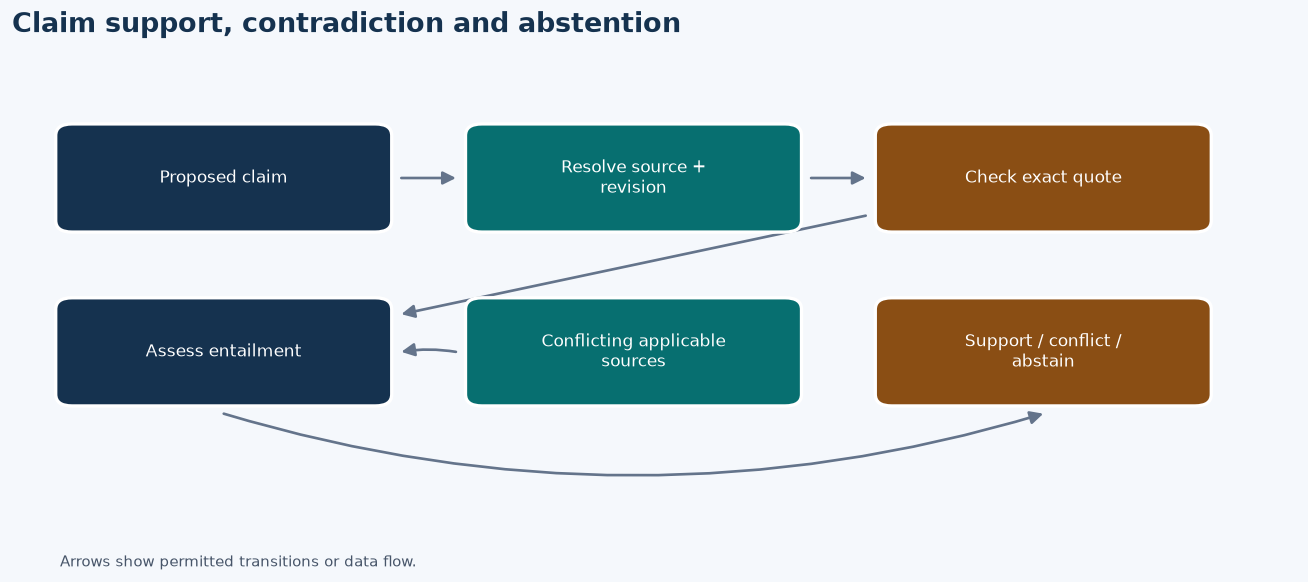

In [2]:
display(diagram('Claim support, contradiction and abstention', ['Proposed claim', 'Resolve source + revision', 'Check exact quote', 'Assess entailment', 'Conflicting applicable sources', 'Support / conflict / abstain'], [(0, 1), (1, 2), (2, 3), (4, 3), (3, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import re
from deep_agent_lab.knowledge import load_policy_evidence
from deep_agent_lab.evidence import Claim,Reference,validate_references,extractive_verdict
rows = load_policy_evidence(ROOT / "data/sample")
registry = {row.id:row for row in rows}
source = next(row for row in rows if "database operations lead" in row.excerpt)
reference = Reference(evidence_id=source.id,revision=source.revision,quote=source.excerpt)
exact = next(s for s in re.split(r"(?<=[.!?])\s+",source.excerpt) if "lead must approve" in s)
claims = [Claim(text=exact,references=[reference]),
          Claim(text="The database operations lead is forbidden from approving production restores.",references=[reference]),
          Claim(text="The restore approver automatically becomes Incident Commander.",references=[reference])]
def provenance_ok(claim):
    return validate_references(claim,registry) == []
assert all(provenance_ok(claim) for claim in claims)
labels = [extractive_verdict(claim,registry).label for claim in claims]
assert labels == ["supported","insufficient","insufficient"]
print(labels)


['supported', 'insufficient', 'insufficient']


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Inspect the actual service configuration and returned observations in each cell.

In [4]:
from deep_agent_lab.evidence import model_verdict
from deep_agent_lab.model_lab import course_model
verdicts = [model_verdict(course_model(),claim,registry) for claim in claims]
print([v.model_dump() for v in verdicts])


[{'label': 'supported', 'reason': "The evidence explicitly states: 'To restore accidentally deleted customer records, open a restore request with the database operations team. The database operations lead must approve a production restore.' This directly supports the claim that the database operations lead must approve a production restore.", 'method': 'model'}, {'label': 'contradicted', 'reason': "The evidence explicitly states that 'The database operations lead must approve a production restore,' which directly contradicts the claim that they are forbidden from doing so.", 'method': 'model'}, {'label': 'contradicted', 'reason': "The evidence states that to restore accidentally deleted records, one must 'open a restore request with the database operations team' and that 'The database operations lead must approve a production restore.' It does not mention an automatic transition of roles or becoming an Incident Commander upon approval. In fact, the process described involves specific o

## Code walkthrough

Membership, coverage and support answer different questions. The extractive verifier accepts complete source sentences and abstains on paraphrases; it is deliberately conservative and does not infer contradiction from keywords. For general prose, model_verdict invokes an actual configured LangChain model, but that prediction needs human calibration. PolicyFact comparisons assume human-curated slots with matched scope; they are not automatic fact extraction. Do not silently choose whichever incompatible policy happened to rank first.

## Interactive experiments

Create two independently applicable source records with incompatible approving roles. Keep their provenance and return both as a conflict. A superseded revision of the same source should instead be removed by canonical hydration.

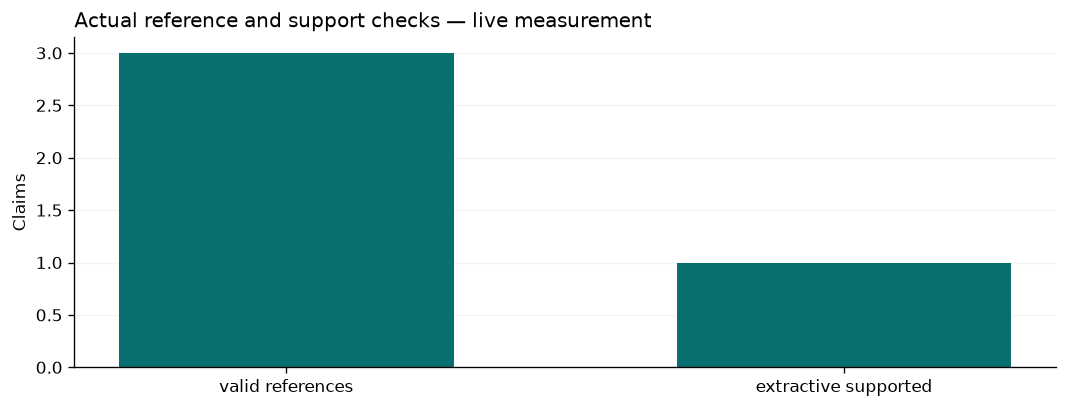

The canonical corpus has one applicable restore approver. Contradictory source handling is exercised in unit tests.


In [5]:
display(bars("Actual reference and support checks",
    {"valid references":sum(provenance_ok(c) for c in claims),"extractive supported":labels.count("supported")},
    measurement_kind="live measurement",ylabel="Claims"))
plt.close("all")
print("The canonical corpus has one applicable restore approver. Contradictory source handling is exercised in unit tests.")


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
for change,expected in [({"evidence_id":"fabricated"},"unknown_evidence"),
                        ({"revision":"99"},"revision_mismatch"),
                        ({"quote":"made up quotation"},"excerpt_not_in_source")]:
    bad = Claim(text=claims[0].text,references=[reference.model_copy(update=change)])
    assert expected in validate_references(bad,registry)
assert "missing_evidence" in validate_references(Claim(text="Unsupported statement"),registry)
print("Unknown, stale, fabricated and missing references all rejected.")

Unknown, stale, fabricated and missing references all rejected.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert provenance_ok(claims[1]) and extractive_verdict(claims[1],registry).label != "supported"
print("Live model verdicts are observations requiring annotation review.")


Live model verdicts are observations requiring annotation review.


## Exercise

Add a condition to a copied claim, such as 'only for staging'. Verify that the complete-sentence extractive verifier refuses to promote the modified statement.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
conditional = claims[0].model_copy(update={"text":"The database operations lead approves production restores only for staging."})
assert validate_references(conditional,registry) == []
assert extractive_verdict(conditional,registry).label == "insufficient"
print("Valid quotation cannot authorize an unsupported condition.")

Valid quotation cannot authorize an unsupported condition.


## Trade-offs and further reading

More candidates or reranking can improve recall at additional latency. An empty successful search permits a bounded reformulation; a failed backend must be reported as unavailable. Source changes require rechecking active revisions. The companion evidence notebook examines provenance, conflict and semantic limits in depth.

[Primary source 1](https://docs.opensearch.org/latest/search-plugins/keyword-search/) Â· [Primary source 2](https://docs.langchain.com/oss/python/deepagents/retrieval)

## Integrated service extension

Configure the actual services described in `docs/operations.md`. This cell executes
real retrieval and model calls. Inspect source revisions, tool results and evidence gaps.
Model output still requires claim support review. External telemetry export is disabled.


In [9]:
RUN_LIVE = True
if RUN_LIVE:
    from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
    live = Settings(_env_file=ROOT / ".env", deep_lab_mode="live", langfuse_enabled=False)
    live.deep_lab_state_dir = Path(scratch.name) / "extension"
    with open_checkpointer(live) as cp:
        service = AgentService(live, cp)
        try:
            result = service.run(RunRequest(
                prompt="Who approves a production restore? Cite the policy."))
            print(result.model_dump_json(indent=2))
            assert result.evidence and not result.unknown_citations
        finally:
            service.close()


{
  "thread_id": "e6ad553353684d868a5de5730d2083f7",
  "status": "completed",
  "answer": "Based on the policy search results, here is who approves a production restore:\n\n**The database operations lead must approve a production restore.**\n\nThis is stated in the backup-policy document:\n\n> \"To restore accidentally deleted customer records, open a restore request with the database operations team. **The database operations lead must approve a production restore**. Restore into an isolated database first, verify the requested records, and agree on the recovery plan before changing production.\" [[fbac2beaa4c7]]\n\n**Key approval process steps:**\n1. Open a restore request with the database operations team\n2. **Database operations lead approves** the production restore\n3. Restore into an isolated database first\n4. Verify the requested records\n5. Agree on the recovery plan before changing production",
  "evidence": [
    {
      "id": "8689ba038dbf7103d7964482372c286fecd73e9c2441d

In [10]:
plt.close('all')
scratch.cleanup()
print('All executed module assertions passed.')

All executed module assertions passed.
